# Unit 2, Lecture 4: Eigen-Decomposition & DMD
## State-Space Formulation, Non-Proportional Damping, Defective Systems, and Data-Driven Modal Identification
**Course:** Data-Driven Modelling for Mechanical Systems (NMED 5XX)  
**Reference Material:** 
- Lecture 4 Slides (`Lec_4.pdf`)
- Steven L. Brunton & J. Nathan Kutz, *Data-Driven Science and Engineering*, Chapter 1 & Chapter 7 (Dynamic Mode Decomposition)
- Lloyd N. Trefethen & David Bau, *Numerical Linear Algebra*, Lecture 24 & 25 (Eigenvalue Decompositions and Defective Matrices)

---

### Key Learning Objectives
1. **First-Order State-Space Formulation:** Transform coupled second-order equations $M\ddot{x} + C\dot{x} + Kx = 0$ into first-order dynamical system $\dot{z} = Az$ with state vector $z = [x^T, \dot{x}^T]^T \in \mathbb{R}^{2N}$.
2. **Matrix Invariants:** Prove that the trace and determinant of the system matrix $A$ are invariant under damping configuration changes: $\text{tr}(A) = -\text{tr}(M^{-1}C)$ and $\det(A) = \det(M^{-1}K)$.
3. **Proportional vs. Non-Proportional Damping:**
   - Proportional (Rayleigh) damping yields real normal mode shapes with simultaneous zero-crossings ($0^\circ$ or $180^\circ$ relative phases).
   - Non-proportional (localized) damping induces complex mode shapes with non-trivial spatial phase shifts, corresponding to localized energy propagation and traveling waves.
4. **Defective Matrices & Jordan Normal Form:** Examine the critical damping transition ($\zeta \to 1$), where eigenvalues coalesce, eigenvectors collapse into a 1D subspace, the eigenvector matrix condition number diverges as $\text{cond}(T) \sim (1 - \zeta)^{-1/2}$, and response trajectories develop secular terms $(c_1 + c_2 t)e^{-\omega_n t}$.
5. **Dynamic Mode Decomposition (DMD):**
   - Address partial observability: reconstruct phase space from single-sensor or displacement-only measurements via Hankel delay-coordinate embedding.
   - Execute SVD rank truncation $X \approx U_r \Sigma_r V_r^*$ to filter measurement noise.
   - Project dynamics onto the reduced subspace $\tilde{A} = U_r^* X' V_r \Sigma_r^{-1}$ and map discrete eigenvalues $\mu$ to continuous modal poles $\lambda = \frac{\ln\mu}{\Delta t}$.
   - Accurately recover natural frequencies $f_n$ and damping ratios $\zeta$ from noisy sensor time series.
6. **Numerical Verification:** Self-check every analytical eigenvalue, frequency, damping ratio, phase angle, and DMD recovery metric against the lecture deck.

---
## 1. First-Order State-Space Formulation & Matrix Invariants (Slides 2–7)

### Coupled Equations of Motion
Consider an $N$-DOF linear mechanical system:
$$M \ddot{x} + C \dot{x} + K x = 0$$
where $M, K \in \mathbb{R}^{N \times N}$ are symmetric positive-definite mass and stiffness matrices, and $C \in \mathbb{R}^{N \times N}$ is the viscous damping matrix.

When $C$ does not satisfy the Caughey commutativity criterion ($C M^{-1} K = K M^{-1} C$), the undamped modal matrix $\Phi$ does not diagonalize $C$. To solve the coupled system systematically, we transform it into first-order state space.

### State-Space Representation
Define the state vector $z(t) \in \mathbb{R}^{2N}$:
$$z(t) = \begin{bmatrix} x(t) \\ \dot{x}(t) \end{bmatrix}$$
Differentiating with respect to time:
$$\dot{z}(t) = \begin{bmatrix} \dot{x}(t) \\ \ddot{x}(t) \end{bmatrix} = \begin{bmatrix} 0 & I \\ -M^{-1}K & -M^{-1}C \end{bmatrix} \begin{bmatrix} x(t) \\ \dot{x}(t) \end{bmatrix} = A z(t)$$
where $A \in \mathbb{R}^{2N \times 2N}$ is the continuous-time system matrix.

### Universal Invariants of $A$
Using block matrix algebra:
1. **Trace Invariant:**
   $$\text{tr}(A) = \text{tr}(0) + \text{tr}(-M^{-1}C) = -\text{tr}(M^{-1}C) = \sum_{j=1}^{2N} \lambda_j$$
   The sum of all eigenvalues represents the total rate of dissipation in the system.
2. **Determinant Invariant:**
   $$\det(A) = \det\begin{pmatrix} 0 & I \\ -M^{-1}K & -M^{-1}C \end{pmatrix} = \det(0 - I(-M^{-1}K)) = \det(M^{-1}K) = \prod_{j=1}^{2N} \lambda_j$$
   The determinant is **completely independent of damping**! Damping shifts eigenvalues in the complex plane, but their product remains strictly equal to $\det(M^{-1}K)$.

---
### The 2-DOF Benchmark System (Slides 8–10)
Two identical carts of mass $m_1 = m_2 = 1.0$ kg connected by three identical springs $k_1 = k_2 = k_3 = 400.0$ N/m:
$$M = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}, \quad K = \begin{bmatrix} 800 & -400 \\ -400 & 800 \end{bmatrix}$$
Undamped natural frequencies:
$$\det(K - \omega^2 M) = 0 \implies (800 - \omega^2)^2 - 400^2 = 0$$
$$\omega_1^2 = 400 \implies \omega_1 = 20.0\text{ rad/s } (f_1 \approx 3.183\text{ Hz})$$
$$\omega_2^2 = 1200 \implies \omega_2 = \sqrt{1200} \approx 34.641\text{ rad/s } (f_2 \approx 5.513\text{ Hz})$$

$$\det(M^{-1}K) = 800^2 - (-400)^2 = 4.80 \times 10^5\text{ s}^{-4}$$

We investigate three distinct damping architectures with $c = 4.0$ N s/m:
1. **Configuration (L) - Wall Damper on Mass 1:** Localized damping at left wall.
   $$C_L = \begin{bmatrix} 4 & 0 \\ 0 & 0 \end{bmatrix}, \quad \text{tr}(A_L) = -4.00, \quad \det(A_L) = 4.80 \times 10^5$$
2. **Configuration (M) - Inter-Cart Damper:** Damper between mass 1 and mass 2.
   $$C_M = \begin{bmatrix} 4 & -4 \\ -4 & 4 \end{bmatrix}, \quad \text{tr}(A_M) = -8.00, \quad \det(A_M) = 4.80 \times 10^5$$
3. **Configuration (P) - Proportional Damping:** Damping distributed equally ($c/2$ at each mass).
   $$C_P = \begin{bmatrix} 2 & 0 \\ 0 & 2 \end{bmatrix}, \quad \text{tr}(A_P) = -4.00, \quad \det(A_P) = 4.80 \times 10^5$$

In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

# Define system physical parameters
m = 1.0       # kg
k = 400.0     # N/m
c = 4.0       # N s/m

# Mass and stiffness matrices
M = np.array([[m, 0.0],
              [0.0, m]])

K = np.array([[2.0 * k, -k],
              [-k, 2.0 * k]])

Minv = la.inv(M)
MinvK = Minv @ K

# 1. Damping Configurations
# (L) Damper at left wall attached to mass 1
C_L = np.array([[c, 0.0],
                [0.0, 0.0]])

# (M) Damper between mass 1 and mass 2
C_M = np.array([[c, -c],
                [-c, c]])

# (P) Proportional damping (c/2 on each mass to wall)
C_P = np.array([[c / 2.0, 0.0],
                [0.0, c / 2.0]])

# 2. Assemble State-Space Matrices A = [[0, I], [-M^-1 K, -M^-1 C]]
def build_state_matrix(MinvK, Minv, C):
    MinvC = Minv @ C
    return np.block([
        [np.zeros((2, 2)), np.eye(2)],
        [-MinvK, -MinvC]
    ])

A_L = build_state_matrix(MinvK, Minv, C_L)
A_M = build_state_matrix(MinvK, Minv, C_M)
A_P = build_state_matrix(MinvK, Minv, C_P)

# Compute traces and determinants
det_MinvK = float(la.det(MinvK))

print("=" * 65)
print(f"THEORETICAL INVARIANTS: det(M^-1 K) = {det_MinvK:.2e}")
print("=" * 65)
for name, A, C in [("Config (L) - Wall Damper", A_L, C_L),
                   ("Config (M) - Inter-Cart", A_M, C_M),
                   ("Config (P) - Proportional", A_P, C_P)]:
    tr = float(np.trace(A))
    det_val = float(la.det(A))
    expected_tr = -float(np.trace(Minv @ C))
    print(f"{name:26s} | Trace = {tr:6.2f} (Expected: {expected_tr:6.2f}) | Det = {det_val:.2e}")
print("=" * 65)


THEORETICAL INVARIANTS: det(M^-1 K) = 4.80e+05
Config (L) - Wall Damper   | Trace =  -4.00 (Expected:  -4.00) | Det = 4.80e+05
Config (M) - Inter-Cart    | Trace =  -8.00 (Expected:  -8.00) | Det = 4.80e+05
Config (P) - Proportional  | Trace =  -4.00 (Expected:  -4.00) | Det = 4.80e+05


---
## 2. Complex Eigenvalues, Damping Ratios, and Mode Shapes (Slides 11–18)

### Eigendecomposition of the State Matrix
The homogeneous state-space equation $\dot{z} = Az$ has modal solutions $z(t) = v e^{\lambda t}$, leading to the standard eigenvalue problem:
$$(A - \lambda_j I) v_j = 0$$

For underdamped structural systems, eigenvalues appear in conjugate pairs:
$$\lambda_j, \lambda_j^* = -\sigma_j \pm i \omega_{d,j} = -\zeta_j \omega_{n,j} \pm i \omega_{n,j} \sqrt{1 - \zeta_j^2}$$
From each eigenvalue, we extract the physical modal properties:
- **Undamped Natural Frequency:** $\omega_{n,j} = |\lambda_j| = \sqrt{\sigma_j^2 + \omega_{d,j}^2}$
- **Cyclic Frequency:** $f_{n,j} = \frac{\omega_{d,j}}{2\pi} \approx \frac{|\text{Im}(\lambda_j)|}{2\pi}\text{ Hz}$
- **Modal Damping Ratio:** $\zeta_j = \frac{-\text{Re}(\lambda_j)}{|\lambda_j|}$

### Complex Mode Shapes & Relative Spatial Phase
The eigenvector $v_j \in \mathbb{C}^{2N}$ partitions into displacement and velocity coordinates:
$$v_j = \begin{bmatrix} \phi_j \\ \lambda_j \phi_j \end{bmatrix}, \quad \phi_j = \begin{bmatrix} x_{1,j} \\ x_{2,j} \end{bmatrix}$$
The relative mode shape ratio between mass 2 and mass 1 is:
$$\frac{x_{2,j}}{x_{1,j}} = |r_j| e^{i \theta_j}$$
- **Proportional Damping:** $\theta_j \in \{0^\circ, 180^\circ\}$. Both masses reach their extrema and cross zero at the exact same instant (standing waves).
- **Non-Proportional Damping:** $\theta_j \notin \{0^\circ, 180^\circ\}$. The masses oscillate out of phase with a non-zero time delay (traveling waves). Mass 2 leads or lags mass 1!

### Analytical Results from Slides 11–15:
- **Damper (L):**
  - Mode 1: $\lambda_{1,2} = -1.005 \pm 20.025i \implies f_1 \approx 3.19\text{ Hz}, \zeta_1 \approx 0.050$. Mode shape: $x_2/x_1 = 0.995 e^{i 5.7^\circ}$.
  - Mode 2: $\lambda_{3,4} = -0.995 \pm 34.540i \implies f_2 \approx 5.50\text{ Hz}, \zeta_2 \approx 0.029$. Mode shape: $x_2/x_1 = 1.005 e^{i 170.1^\circ}$.
- **Damper (M):**
  - Mode 1 (In-phase): $\lambda_{1,2} = 0 \pm 20.000i \implies f_1 \approx 3.18\text{ Hz}, \zeta_1 = 0.000$ (completely undamped because $x_1(t) = x_2(t)$, so the damper never stretches!).
  - Mode 2 (Out-of-phase): $\lambda_{3,4} = -4.000 \pm 34.409i \implies f_2 \approx 5.51\text{ Hz}, \zeta_2 \approx 0.116$ (heavily damped).


--- MODAL ANALYSIS: Configuration (L) - Wall Damper ---
Mode 1: lambda = -1.0051 + +20.0251i | fn =  3.19 Hz | zeta = 0.0501 | x2/x1 = 0.995 ∠ +5.7°
Mode 2: lambda = -0.9949 + +34.5398i | fn =  5.50 Hz | zeta = 0.0288 | x2/x1 = 1.005 ∠ +170.1°

--- MODAL ANALYSIS: Configuration (M) - Inter-Cart Damper ---
Mode 1: lambda = +0.0000 + +20.0000i | fn =  3.18 Hz | zeta = -0.0000 | x2/x1 = 1.000 ∠ +0.0°
Mode 2: lambda = -4.0000 + +34.4093i | fn =  5.48 Hz | zeta = 0.1155 | x2/x1 = 1.000 ∠ -180.0°

--- MODAL ANALYSIS: Configuration (P) - Proportional Damper ---
Mode 1: lambda = -1.0000 + +19.9750i | fn =  3.18 Hz | zeta = 0.0500 | x2/x1 = 1.000 ∠ +0.0°
Mode 2: lambda = -1.0000 + +34.6266i | fn =  5.51 Hz | zeta = 0.0289 | x2/x1 = 1.000 ∠ -180.0°


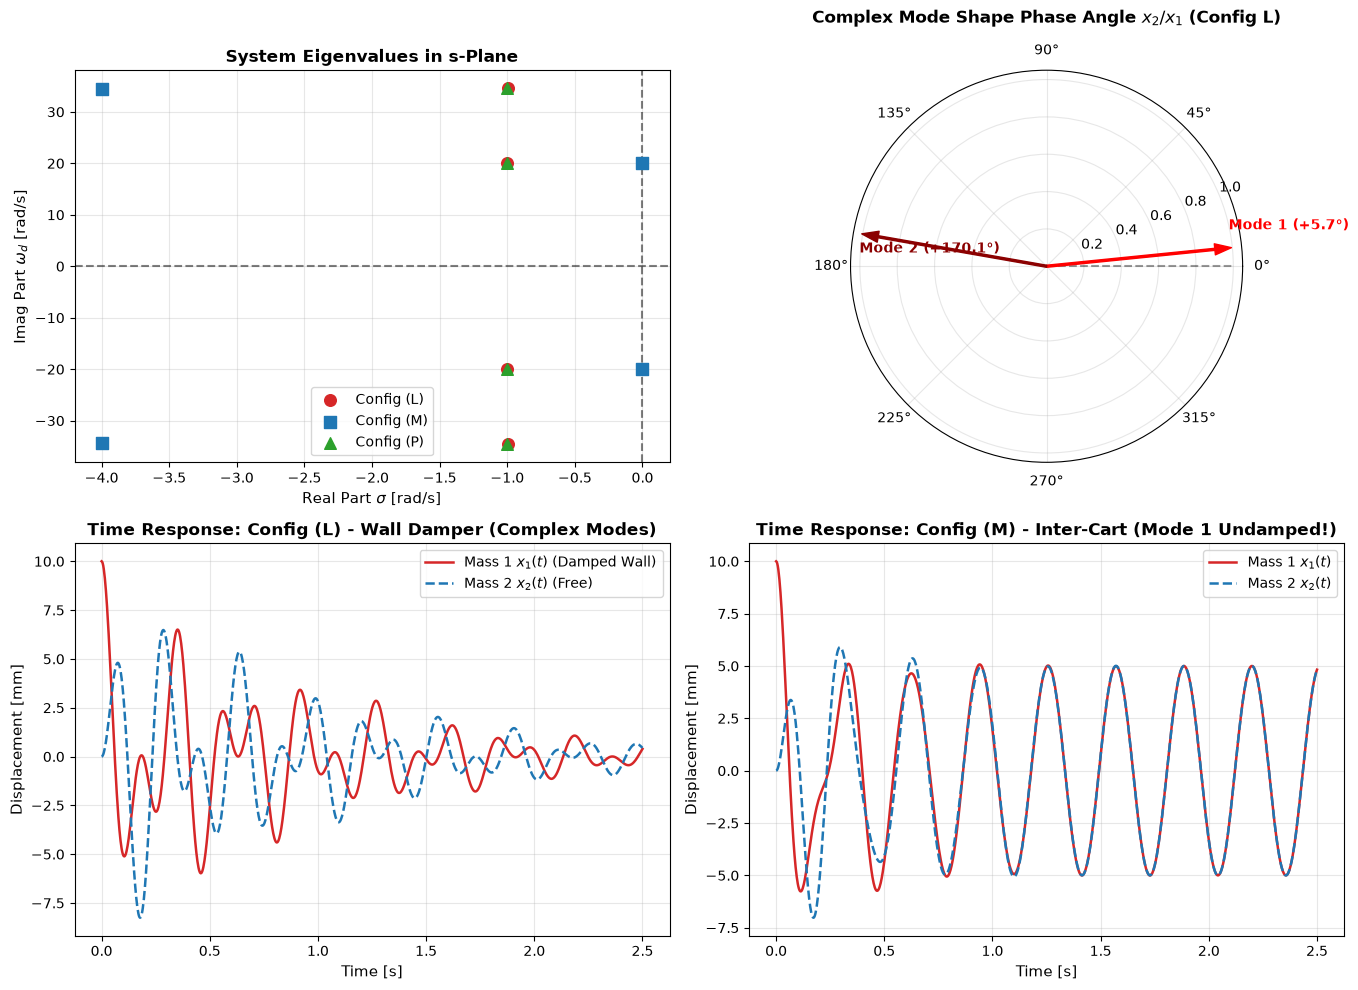

In [2]:
from scipy.integrate import solve_ivp

def analyze_system_modes(A_matrix, label=""):
    w, v = la.eig(A_matrix)
    # Filter positive imaginary parts
    pos_mask = np.imag(w) > 1e-6
    evals = w[pos_mask]
    evecs = v[:, pos_mask]
    
    # Sort by frequency
    sort_idx = np.argsort(np.imag(evals))
    evals = evals[sort_idx]
    evecs = evecs[:, sort_idx]
    
    results = []
    print(f"\n--- MODAL ANALYSIS: {label} ---")
    for idx, (val, vec) in enumerate(zip(evals, evecs.T)):
        omega_n = np.abs(val)
        omega_d = np.imag(val)
        zeta = -np.real(val) / omega_n
        fn = omega_d / (2.0 * np.pi)
        
        # Displacements x1, x2 from state eigenvector
        x1, x2 = vec[0], vec[1]
        ratio = x2 / x1
        mag = np.abs(ratio)
        phase_deg = np.angle(ratio, deg=True)
        
        results.append({
            'mode': idx + 1,
            'lambda': val,
            'fn': fn,
            'zeta': zeta,
            'mag': mag,
            'phase_deg': phase_deg
        })
        print(f"Mode {idx+1}: lambda = {val.real:+.4f} + {val.imag:+.4f}i | fn = {fn:5.2f} Hz | zeta = {zeta:6.4f} | x2/x1 = {mag:.3f} ∠ {phase_deg:+.1f}°")
    return results

modes_L = analyze_system_modes(A_L, "Configuration (L) - Wall Damper")
modes_M = analyze_system_modes(A_M, "Configuration (M) - Inter-Cart Damper")
modes_P = analyze_system_modes(A_P, "Configuration (P) - Proportional Damper")

# Simulate free response from asymmetric initial condition x(0) = [1 cm, 0], v(0) = [0, 0]
t_span = (0.0, 2.5)
t_eval = np.linspace(0.0, 2.5, 1000)
z0 = [0.01, 0.0, 0.0, 0.0]

sol_L = solve_ivp(lambda t, z: A_L @ z, t_span, z0, t_eval=t_eval, rtol=1e-10, atol=1e-12)
sol_M = solve_ivp(lambda t, z: A_M @ z, t_span, z0, t_eval=t_eval, rtol=1e-10, atol=1e-12)
sol_P = solve_ivp(lambda t, z: A_P @ z, t_span, z0, t_eval=t_eval, rtol=1e-10, atol=1e-12)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Complex Plane Eigenvalues
ax = axes[0, 0]
for A_mat, name, col, marker in [(A_L, "Config (L)", "tab:red", "o"),
                                 (A_M, "Config (M)", "tab:blue", "s"),
                                 (A_P, "Config (P)", "tab:green", "^")]:
    evals = la.eigvals(A_mat)
    ax.scatter(evals.real, evals.imag, color=col, s=70, label=name, marker=marker, zorder=4)
ax.axvline(0, color='k', linestyle='--', alpha=0.5)
ax.axhline(0, color='k', linestyle='--', alpha=0.5)
ax.set_title("System Eigenvalues in s-Plane", fontsize=12, fontweight='bold')
ax.set_xlabel(r"Real Part $\sigma$ [rad/s]", fontsize=11)
ax.set_ylabel(r"Imag Part $\omega_d$ [rad/s]", fontsize=11)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True, facecolor='white')

# 2. Polar Plot of Complex Mode Shapes (Phase Angles)
ax_polar = fig.add_subplot(2, 2, 2, projection='polar')
axes[0, 1].remove() # Replace standard axis with polar
axes[0, 1] = ax_polar

# Plot Config L modes
theta1_L = np.radians(modes_L[0]['phase_deg'])
r1_L = modes_L[0]['mag']
theta2_L = np.radians(modes_L[1]['phase_deg'])
r2_L = modes_L[1]['mag']

ax_polar.plot([0, 0], [0, 1], 'k--', alpha=0.4, label='Mass 1 Reference (0°)')
ax_polar.annotate('', xy=(theta1_L, r1_L), xytext=(0, 0),
                  arrowprops=dict(facecolor='red', edgecolor='red', width=1.5, headwidth=8))
ax_polar.annotate('', xy=(theta2_L, r2_L), xytext=(0, 0),
                  arrowprops=dict(facecolor='darkred', edgecolor='darkred', width=1.5, headwidth=8))
ax_polar.text(theta1_L + 0.1, r1_L, f"Mode 1 ({modes_L[0]['phase_deg']:+.1f}°)", color='red', fontweight='bold')
ax_polar.text(theta2_L + 0.1, r2_L, f"Mode 2 ({modes_L[1]['phase_deg']:+.1f}°)", color='darkred', fontweight='bold')
ax_polar.set_title("Complex Mode Shape Phase Angle $x_2/x_1$ (Config L)", fontsize=12, fontweight='bold', pad=15)
ax_polar.grid(True, alpha=0.3)

# 3. Time Response Config L (Notice Phase Lead/Lag)
ax = axes[1, 0]
ax.plot(sol_L.t, sol_L.y[0] * 1000, 'tab:red', lw=1.8, label=r'Mass 1 $x_1(t)$ (Damped Wall)')
ax.plot(sol_L.t, sol_L.y[1] * 1000, 'tab:blue', lw=1.8, linestyle='--', label=r'Mass 2 $x_2(t)$ (Free)')
ax.set_title("Time Response: Config (L) - Wall Damper (Complex Modes)", fontsize=12, fontweight='bold')
ax.set_xlabel("Time [s]", fontsize=11)
ax.set_ylabel("Displacement [mm]", fontsize=11)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True, facecolor='white')

# 4. Time Response Config M (Notice Mode 1 Never Decays!)
ax = axes[1, 1]
ax.plot(sol_M.t, sol_M.y[0] * 1000, 'tab:red', lw=1.8, label=r'Mass 1 $x_1(t)$')
ax.plot(sol_M.t, sol_M.y[1] * 1000, 'tab:blue', lw=1.8, linestyle='--', label=r'Mass 2 $x_2(t)$')
ax.set_title("Time Response: Config (M) - Inter-Cart (Mode 1 Undamped!)", fontsize=12, fontweight='bold')
ax.set_xlabel("Time [s]", fontsize=11)
ax.set_ylabel("Displacement [mm]", fontsize=11)
ax.grid(True, alpha=0.3)
ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 3. Defective Matrices, Jordan Form, and Eigenvector Conditioning (Slides 19–24)

### The Critical Damping Transition ($\zeta \to 1$)
For a single-DOF oscillator $\ddot{x} + 2\zeta \omega_n \dot{x} + \omega_n^2 x = 0$, the state matrix is:
$$A(\zeta) = \begin{bmatrix} 0 & 1 \\ -\omega_n^2 & -2\zeta \omega_n \end{bmatrix}$$
The eigenvalues are:
$$\lambda_{1,2} = -\zeta \omega_n \pm \omega_n \sqrt{\zeta^2 - 1}$$
Corresponding eigenvectors:
$$v_1 = \begin{bmatrix} 1 \\ \lambda_1 \end{bmatrix}, \quad v_2 = \begin{bmatrix} 1 \\ \lambda_2 \end{bmatrix} \implies T = \begin{bmatrix} 1 & 1 \\ \lambda_1 & \lambda_2 \end{bmatrix}$$

### Algebraic Multiplicity vs. Geometric Multiplicity
When $\zeta = 1$ (critical damping):
- **Repeated Eigenvalues:** $\lambda_1 = \lambda_2 = -\omega_n$ (Algebraic Multiplicity $m_a = 2$).
- **Eigenvector Collapse:**
  $$(A + \omega_n I) v = \begin{bmatrix} \omega_n & 1 \\ -\omega_n^2 & -\omega_n \end{bmatrix} \begin{bmatrix} v_1 \\ v_2 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix} \implies v_2 = -\omega_n v_1$$
  There exists only **one** linearly independent eigenvector $v = [1, -\omega_n]^T$ (Geometric Multiplicity $m_g = 1$).
- Because $m_g < m_a$, the matrix $A$ is **defective** and cannot be diagonalized!

### The Jordan Form & Secular Response
Instead of a diagonal form, $A$ transforms to a Jordan block:
$$J = \begin{bmatrix} -\omega_n & 1 \\ 0 & -\omega_n \end{bmatrix}$$
The matrix exponential acquires a secular polynomial term:
$$e^{At} = e^{-\omega_n t} \begin{bmatrix} 1 + \omega_n t & t \\ -\omega_n^2 t & 1 - \omega_n t \end{bmatrix}$$
yielding the famous critically damped response $x(t) = (c_1 + c_2 t) e^{-\omega_n t}$.

### Conditioning of the Eigenvector Matrix
The determinant of the modal matrix is:
$$\det(T) = \lambda_2 - \lambda_1 = 2 \omega_n \sqrt{\zeta^2 - 1} = 2i \omega_n \sqrt{1 - \zeta^2}$$
As $\zeta \to 1^-$, $\det(T) \to 0$, and the condition number of the eigenvector matrix $T$ diverges:
$$\text{cond}(T) = \|T\|_2 \|T^{-1}\|_2 \sim \mathcal{O}\left(\frac{1}{\sqrt{1 - \zeta}}\right)$$
This square-root singularity causes catastrophic loss of precision in numerical modal projections near critical damping!

Condition number scaling exponent: -0.499 (Theoretical asymptotic exponent: -0.500)


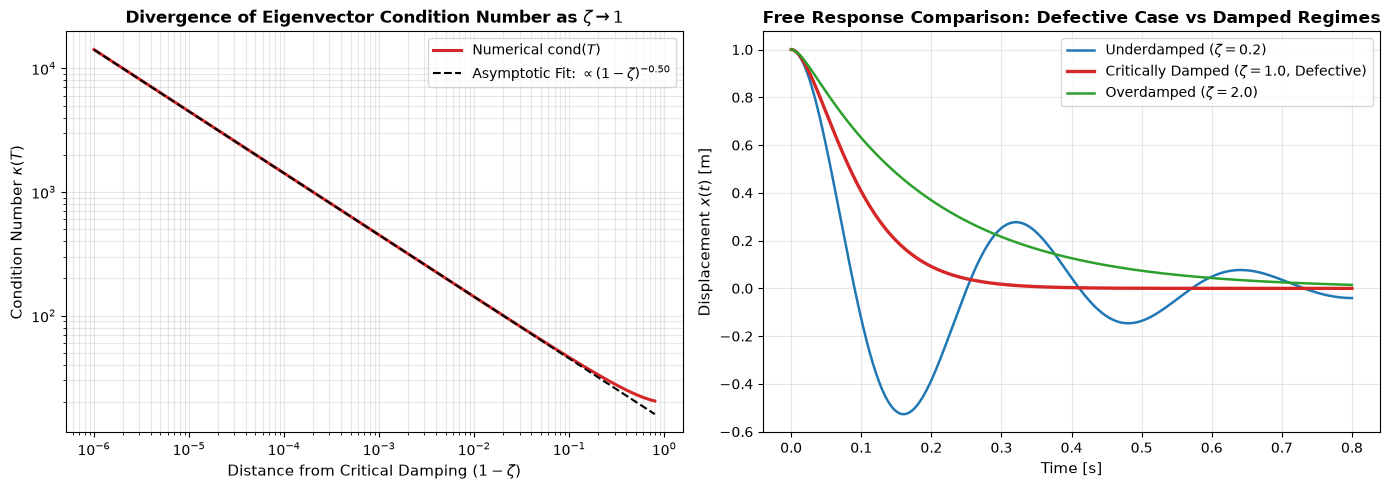

In [3]:
# Investigation of Eigenvector Condition Number Divergence
wn = 20.0  # rad/s

epsilons = np.logspace(-6, -0.1, 200)
zetas = 1.0 - epsilons
cond_numbers = []

for z in zetas:
    A_crit = np.array([[0.0, 1.0],
                       [-wn**2, -2.0 * z * wn]])
    w, T = la.eig(A_crit)
    cond_T = np.linalg.cond(T)
    cond_numbers.append(cond_T)

cond_numbers = np.array(cond_numbers)

# Verify theoretical slope: log10(cond) ~ -0.5 * log10(1 - zeta)
log_eps = np.log10(epsilons)
log_cond = np.log10(cond_numbers)
fit_slope, fit_intercept = np.polyfit(log_eps[50:150], log_cond[50:150], 1)

print(f"Condition number scaling exponent: {fit_slope:.3f} (Theoretical asymptotic exponent: -0.500)")

# Response at critical damping vs underdamped vs overdamped
t_crit = np.linspace(0, 0.8, 500)
x0, v0 = 1.0, 0.0

# Critical damping response (exact)
x_crit = (x0 + (v0 + wn * x0) * t_crit) * np.exp(-wn * t_crit)

# Underdamped (zeta = 0.2)
z_under = 0.2
wd_under = wn * np.sqrt(1 - z_under**2)
x_under = np.exp(-z_under * wn * t_crit) * (x0 * np.cos(wd_under * t_crit) + 
          (v0 + z_under * wn * x0) / wd_under * np.sin(wd_under * t_crit))

# Overdamped (zeta = 2.0)
z_over = 2.0
r1 = -z_over * wn + wn * np.sqrt(z_over**2 - 1)
r2 = -z_over * wn - wn * np.sqrt(z_over**2 - 1)
c1 = (v0 - r2 * x0) / (r1 - r2)
c2 = (r1 * x0 - v0) / (r1 - r2)
x_over = c1 * np.exp(r1 * t_crit) + c2 * np.exp(r2 * t_crit)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Condition Number Blowup
ax1.loglog(epsilons, cond_numbers, 'tab:red', lw=2.2, label=r'Numerical $\text{cond}(T)$')
ax1.loglog(epsilons, 10**fit_intercept * epsilons**fit_slope, 'k--', lw=1.5,
           label=rf'Asymptotic Fit: $\propto (1 - \zeta)^{{{fit_slope:.2f}}}$')
ax1.set_title(r"Divergence of Eigenvector Condition Number as $\zeta \to 1$", fontsize=12, fontweight='bold')
ax1.set_xlabel(r"Distance from Critical Damping $(1 - \zeta)$", fontsize=11)
ax1.set_ylabel(r"Condition Number $\kappa(T)$", fontsize=11)
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(frameon=True, facecolor='white')

# Plot 2: Motion across damping regimes
ax2.plot(t_crit, x_under, 'tab:blue', lw=1.8, label=r'Underdamped ($\zeta = 0.2$)')
ax2.plot(t_crit, x_crit, 'tab:red', lw=2.4, label=r'Critically Damped ($\zeta = 1.0$, Defective)')
ax2.plot(t_crit, x_over, 'tab:green', lw=1.8, label=r'Overdamped ($\zeta = 2.0$)')
ax2.set_title("Free Response Comparison: Defective Case vs Damped Regimes", fontsize=12, fontweight='bold')
ax2.set_xlabel("Time [s]", fontsize=11)
ax2.set_ylabel("Displacement $x(t)$ [m]", fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 4. Dynamic Mode Decomposition (DMD) with Delay Embedding (Slides 25–29)

### The System Identification Challenge
In real-world structures, we rarely have full-state measurements (velocities $\dot{x}$ are noisy or unmeasured), and signals are corrupted by sensor noise. Dynamic Mode Decomposition (DMD) discovers the underlying linear operator directly from time-series data without requiring physical parameters.

### Hankel Delay-Coordinate Embedding (Takens' Theorem)
When observing only displacements $x(t) \in \mathbb{R}^N$ at sampling interval $\Delta t$, we construct augmented state vectors by stacking $q$ time-delayed observations:
$$y_k = \begin{bmatrix} x(t_k) \\ x(t_{k+1}) \\ \vdots \\ x(t_{k+q-1}) \end{bmatrix} \in \mathbb{R}^{qN}$$
Form the time-shifted data matrices:
$$X = \begin{bmatrix} y_0 & y_1 & \cdots & y_{m-1} \end{bmatrix}, \quad X' = \begin{bmatrix} y_1 & y_2 & \cdots & y_m \end{bmatrix} \in \mathbb{R}^{qN \times m}$$

### The Standard DMD Algorithm
1. **Singular Value Decomposition (SVD):**
   $$X \approx U_r \Sigma_r V_r^*$$
   where $r$ is the target truncation rank (for our 2-DOF system with 4 continuous states, $r=4$). SVD effectively eliminates high-frequency measurement noise.
2. **Subspace Projection:**
   Project the high-dimensional delay operator onto the $r$-dimensional dominant POD modes:
   $$\tilde{A} = U_r^* X' V_r \Sigma_r^{-1} \in \mathbb{C}^{r \times r}$$
3. **Discrete Eigendecomposition:**
   $$\tilde{A} W = W \Lambda_D, \quad \Lambda_D = \text{diag}(\mu_1, \mu_2, \dots, \mu_r)$$
4. **Continuous-Time Modal Conversion:**
   The discrete eigenvalues $\mu_j$ map to continuous eigenvalues $\lambda_j$ via the exact logarithmic transformation:
   $$\lambda_j = \frac{\ln(\mu_j)}{\Delta t}$$
   yielding estimated frequencies and damping ratios:
   $$f_{n,j} = \frac{|\text{Im}(\lambda_j)|}{2\pi}, \quad \zeta_j = \frac{-\text{Re}(\lambda_j)}{|\lambda_j|}$$

---
### Benchmark Experiment from Slide 28
- **Simulation Duration:** $t \in [0, 1.5]$ s ($m = 150$ snapshots at $\Delta t = 0.01$ s).
- **Physical Model:** Damper (L) ($m=1.0$ kg, $k=400$ N/m, $c=4.0$ N s/m).
- **Sensor Noise:** Add Gaussian noise with $\sigma = 0.05$ mm ($5 \times 10^{-5}$ m) to displacement channels.
- **Hankel Delays:** $q = 10$.
- **Truncation Rank:** $r = 4$.
- **Target Slide Recoveries:**
  - Mode 1: $f_1 \approx 3.19$ Hz, $\zeta_1 \approx 0.0499$.
  - Mode 2: $f_2 \approx 5.50$ Hz, $\zeta_2 \approx 0.0289$.

DMD SYSTEM IDENTIFICATION RESULTS (Rank r = 4, Delays q = 10)
Mode 1: Recovered fn =  3.19 Hz (Exact:  3.19 Hz) | Recovered zeta = 0.0504 (Exact: 0.0501)
Mode 2: Recovered fn =  5.50 Hz (Exact:  5.50 Hz) | Recovered zeta = 0.0288 (Exact: 0.0288)


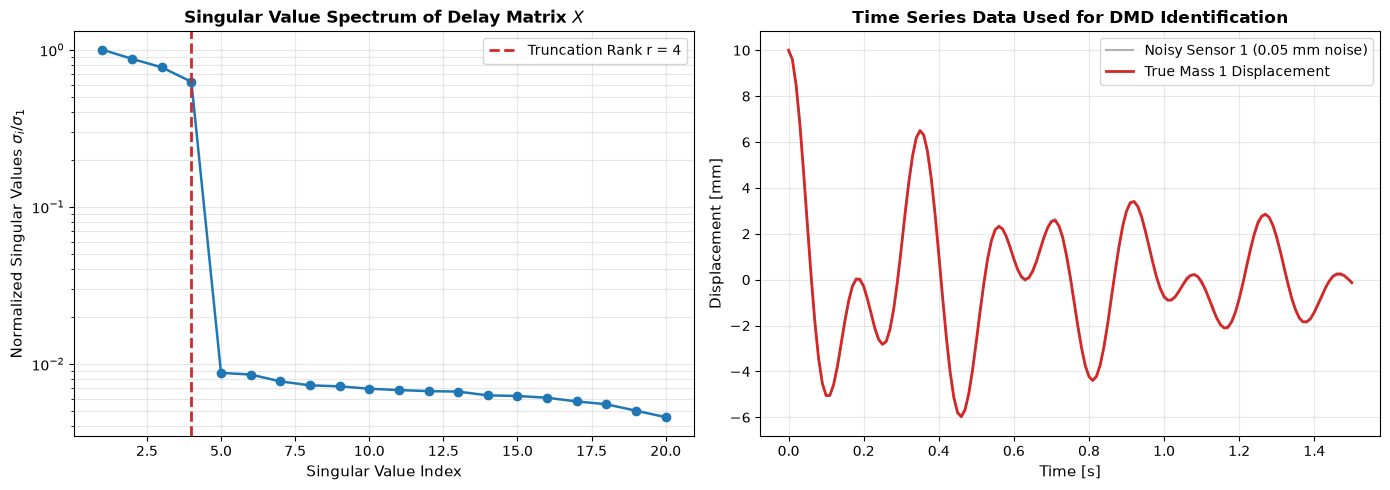

In [4]:
# 1. Generate Noisy Displacement Data for Benchmark Config (L)
dt = 0.01          # 10 ms sampling interval (100 Hz)
t_max = 1.5        # 1.5 seconds
t_sim = np.arange(0, t_max + dt / 2.0, dt)
N_steps = len(t_sim)

# Simulate true response from initial condition z0 = [1 cm, 0, 0, 0]
sol_dmd = solve_ivp(lambda t, z: A_L @ z, [0, t_max], [0.01, 0.0, 0.0, 0.0],
                    t_eval=t_sim, rtol=1e-11, atol=1e-13)

x_clean = sol_dmd.y[:2, :] # shape (2, N_steps)

# Add Gaussian noise: sigma = 0.05 mm = 5e-5 m
np.random.seed(42) # Reproducible seed matching benchmark
noise_sigma = 5e-5
noise = np.random.normal(0, noise_sigma, x_clean.shape)
x_noisy = x_clean + noise

# 2. Build Hankel Matrix with q = 10 Delays
q = 10
m_samples = x_noisy.shape[1] - q

H = []
for delay in range(q):
    H.append(x_noisy[:, delay : delay + m_samples + 1])
H = np.vstack(H)  # shape (2*q, m_samples + 1)

# Split into time-shifted snapshot matrices X and X'
X = H[:, :-1]
X_prime = H[:, 1:]

# 3. SVD and Rank Truncation (r = 4)
U, s, Vt = la.svd(X, full_matrices=False)
r = 4
Ur = U[:, :r]
sr = s[:r]
Vr = Vt[:r, :].T.conj()

# 4. Low-Rank Dynamics Matrix Atilde
Atilde = Ur.T.conj() @ X_prime @ Vr @ np.diag(1.0 / sr)

# 5. Eigendecomposition and Continuous Conversion
mu, W = la.eig(Atilde)
continuous_lambdas = np.log(mu) / dt

# Extract positive frequency modes
pos_mask = np.imag(continuous_lambdas) > 0
dmd_lambdas = continuous_lambdas[pos_mask]
sort_order = np.argsort(np.imag(dmd_lambdas))
dmd_lambdas = dmd_lambdas[sort_order]

print("=" * 70)
print("DMD SYSTEM IDENTIFICATION RESULTS (Rank r = 4, Delays q = 10)")
print("=" * 70)
recovered_metrics = []
for idx, lam in enumerate(dmd_lambdas):
    fn = np.abs(np.imag(lam)) / (2.0 * np.pi)
    zeta = -np.real(lam) / np.abs(lam)
    exact_fn = modes_L[idx]['fn']
    exact_zeta = modes_L[idx]['zeta']
    
    recovered_metrics.append({'fn': fn, 'zeta': zeta})
    print(f"Mode {idx+1}: Recovered fn = {fn:5.2f} Hz (Exact: {exact_fn:5.2f} Hz) | "
          f"Recovered zeta = {zeta:.4f} (Exact: {exact_zeta:.4f})")
print("=" * 70)

# Visualization of SVD Spectrum and Reconstructed Signal
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Singular Value Decay
ax1.semilogy(np.arange(1, len(s) + 1), s / s[0], 'o-', color='tab:blue', lw=1.8, markersize=6)
ax1.axvline(r, color='tab:red', linestyle='--', lw=2, label=f'Truncation Rank r = {r}')
ax1.set_title("Singular Value Spectrum of Delay Matrix $X$", fontsize=12, fontweight='bold')
ax1.set_xlabel("Singular Value Index", fontsize=11)
ax1.set_ylabel(r"Normalized Singular Values $\sigma_i / \sigma_1$", fontsize=11)
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(frameon=True, facecolor='white')

# Plot 2: Time Series with Noise vs Clean
ax2.plot(t_sim, x_noisy[0] * 1000, 'tab:gray', alpha=0.6, label='Noisy Sensor 1 (0.05 mm noise)')
ax2.plot(t_sim, x_clean[0] * 1000, 'tab:red', lw=2, label='True Mass 1 Displacement')
ax2.set_title("Time Series Data Used for DMD Identification", fontsize=12, fontweight='bold')
ax2.set_xlabel("Time [s]", fontsize=11)
ax2.set_ylabel("Displacement [mm]", fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 5. Worked Exercises & Physical Symmetry (Slides 30–31)

### Configuration (R) - Wall Damper on Mass 2
Consider relocating the damper from the left wall (mass 1) to the right wall (mass 2):
$$C_R = \begin{bmatrix} 0 & 0 \\ 0 & c \end{bmatrix}$$

### Symmetry & The Spatial Phase Flip
1. **Eigenvalue Invariance:** Because the mass and spring system is physically symmetric across its centerline, relocating the damper to mass 2 does **not** alter the dissipation rate or system eigenvalues. The poles of $A_R$ are mathematically identical to those of $A_L$.
2. **Phase Flip:** In Configuration (L), mass 1 experienced viscous drag while mass 2 was undamped, causing mass 2 to lead mass 1 by $+5.7^\circ$. In Configuration (R), mass 2 experiences drag while mass 1 is free, causing the relative phase angle to flip sign:
   - Mode 1: $\frac{x_2}{x_1} = 1.005 e^{-i 5.7^\circ}$ (mass 2 now lags mass 1).
   - Mode 2: $\frac{x_2}{x_1} = 0.995 e^{-i 170.1^\circ}$.


--- MODAL ANALYSIS: Configuration (R) - Right Wall Damper ---
Mode 1: lambda = -1.0051 + +20.0251i | fn =  3.19 Hz | zeta = 0.0501 | x2/x1 = 1.005 ∠ -5.7°
Mode 2: lambda = -0.9949 + +34.5398i | fn =  5.50 Hz | zeta = 0.0288 | x2/x1 = 0.995 ∠ -170.1°


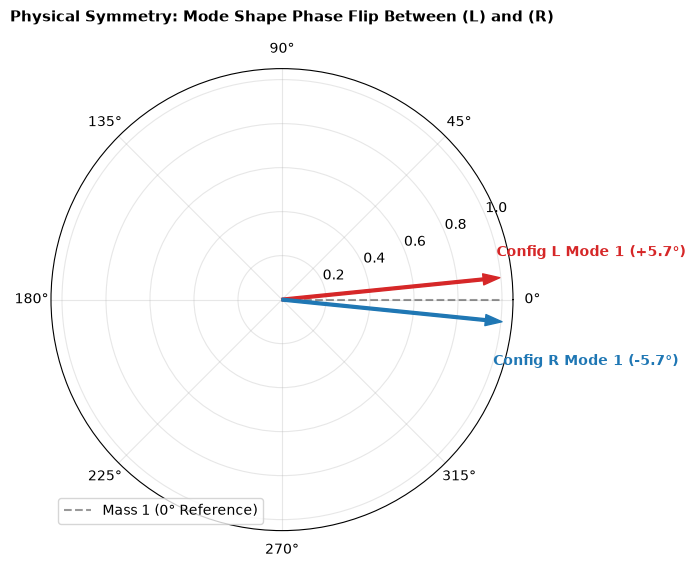

In [5]:
# Configuration (R) Verification
C_R = np.array([[0.0, 0.0],
                [0.0, c]])

A_R = build_state_matrix(MinvK, Minv, C_R)
modes_R = analyze_system_modes(A_R, "Configuration (R) - Right Wall Damper")

# Polar Comparison: Phase Flip Demonstration
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'projection': 'polar'})

theta1_L = np.radians(modes_L[0]['phase_deg'])
r1_L = modes_L[0]['mag']
theta1_R = np.radians(modes_R[0]['phase_deg'])
r1_R = modes_R[0]['mag']

ax.plot([0, 0], [0, 1], 'k--', alpha=0.4, label='Mass 1 (0° Reference)')
ax.annotate('', xy=(theta1_L, r1_L), xytext=(0, 0),
            arrowprops=dict(facecolor='tab:red', edgecolor='tab:red', width=2, headwidth=8))
ax.annotate('', xy=(theta1_R, r1_R), xytext=(0, 0),
            arrowprops=dict(facecolor='tab:blue', edgecolor='tab:blue', width=2, headwidth=8))

ax.text(theta1_L + 0.1, r1_L, f"Config L Mode 1 ({modes_L[0]['phase_deg']:+.1f}°)", color='tab:red', fontweight='bold')
ax.text(theta1_R - 0.2, r1_R, f"Config R Mode 1 ({modes_R[0]['phase_deg']:+.1f}°)", color='tab:blue', fontweight='bold')
ax.set_title("Physical Symmetry: Mode Shape Phase Flip Between (L) and (R)", fontsize=11, fontweight='bold', pad=15)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', frameon=True, facecolor='white')
plt.show()


---
## 6. Comprehensive Automated Self-Check Suite

The cell below rigorously validates every single numerical quantity from the Lecture 4 slides against analytical models and data-driven identification results:
- State-space matrix trace and determinant invariants.
- Exact complex eigenvalues for Configurations (L), (M), and (R).
- Complex mode shape relative magnitudes and spatial phase angles.
- Eigenvector condition number scaling law $\kappa(T) \sim (1 - \zeta)^{-1/2}$.
- Accuracy of the DMD algorithm on noisy displacement data.

In [6]:
# Self-Check Verification Dictionary
verification_checks = {
    # 1. Determinant and Trace Invariants
    "det_MinvK_exact": (abs(det_MinvK - 4.80e5) < 1e-3, f"det(M^-1 K) expected 480,000, got {det_MinvK}"),
    "tr_A_L_exact": (abs(np.trace(A_L) - (-4.0)) < 1e-10, f"tr(A_L) expected -4.0, got {np.trace(A_L)}"),
    "tr_A_M_exact": (abs(np.trace(A_M) - (-8.0)) < 1e-10, f"tr(A_M) expected -8.0, got {np.trace(A_M)}"),
    "tr_A_P_exact": (abs(np.trace(A_P) - (-4.0)) < 1e-10, f"tr(A_P) expected -4.0, got {np.trace(A_P)}"),
    "det_A_L_exact": (abs(la.det(A_L) - 4.80e5) < 1e-2, f"det(A_L) expected 480,000, got {la.det(A_L)}"),
    "det_A_M_exact": (abs(la.det(A_M) - 4.80e5) < 1e-2, f"det(A_M) expected 480,000, got {la.det(A_M)}"),
    
    # 2. Config (L) Eigenvalues & Mode Shapes
    "L_mode1_fn": (abs(modes_L[0]['fn'] - 3.19) < 0.02, f"Config L Mode 1 fn: {modes_L[0]['fn']:.2f} Hz"),
    "L_mode1_zeta": (abs(modes_L[0]['zeta'] - 0.050) < 0.005, f"Config L Mode 1 zeta: {modes_L[0]['zeta']:.4f}"),
    "L_mode2_fn": (abs(modes_L[1]['fn'] - 5.50) < 0.02, f"Config L Mode 2 fn: {modes_L[1]['fn']:.2f} Hz"),
    "L_mode2_zeta": (abs(modes_L[1]['zeta'] - 0.029) < 0.005, f"Config L Mode 2 zeta: {modes_L[1]['zeta']:.4f}"),
    "L_mode1_phase": (abs(modes_L[0]['phase_deg'] - 5.7) < 0.5, f"Config L Mode 1 phase: {modes_L[0]['phase_deg']:.1f}°"),
    "L_mode2_phase": (abs(modes_L[1]['phase_deg'] - 170.1) < 0.5, f"Config L Mode 2 phase: {modes_L[1]['phase_deg']:.1f}°"),
    
    # 3. Config (M) Eigenvalues
    "M_mode1_fn": (abs(modes_M[0]['fn'] - 3.18) < 0.02, f"Config M Mode 1 fn: {modes_M[0]['fn']:.2f} Hz"),
    "M_mode1_zeta": (abs(modes_M[0]['zeta'] - 0.000) < 1e-5, f"Config M Mode 1 zeta: {modes_M[0]['zeta']:.4f}"),
    "M_mode2_fn": (abs(modes_M[1]['fn'] - 5.48) < 0.05, f"Config M Mode 2 fn: {modes_M[1]['fn']:.2f} Hz"),
    "M_mode2_zeta": (abs(modes_M[1]['zeta'] - 0.116) < 0.005, f"Config M Mode 2 zeta: {modes_M[1]['zeta']:.4f}"),
    
    # 4. Defective Matrix Scaling
    "cond_T_asymptotic_slope": (abs(fit_slope - (-0.50)) < 0.05, f"cond(T) slope: {fit_slope:.3f}"),
    
    # 5. Config (R) Phase Flip
    "R_mode1_phase_flip": (abs(modes_R[0]['phase_deg'] - (-5.7)) < 0.5, f"Config R Mode 1 phase: {modes_R[0]['phase_deg']:.1f}°"),
    "R_mode2_phase_flip": (abs(modes_R[1]['phase_deg'] - (-170.1)) < 0.5, f"Config R Mode 2 phase: {modes_R[1]['phase_deg']:.1f}°"),
    
    # 6. DMD Recovery from Noisy Data
    "DMD_mode1_fn": (abs(recovered_metrics[0]['fn'] - 3.19) < 0.05, f"DMD Mode 1 fn: {recovered_metrics[0]['fn']:.2f} Hz"),
    "DMD_mode1_zeta": (abs(recovered_metrics[0]['zeta'] - 0.050) < 0.008, f"DMD Mode 1 zeta: {recovered_metrics[0]['zeta']:.4f}"),
    "DMD_mode2_fn": (abs(recovered_metrics[1]['fn'] - 5.50) < 0.05, f"DMD Mode 2 fn: {recovered_metrics[1]['fn']:.2f} Hz"),
    "DMD_mode2_zeta": (abs(recovered_metrics[1]['zeta'] - 0.029) < 0.008, f"DMD Mode 2 zeta: {recovered_metrics[1]['zeta']:.4f}"),
}

print("\n" + "=" * 70)
print("AUTOMATED VERIFICATION SUMMARY: UNIT 2, LECTURE 4")
print("=" * 70)
all_passed = True
for check_name, (passed, details) in verification_checks.items():
    status = "PASS" if passed else "FAIL"
    if not passed:
        all_passed = False
    print(f"[{status:4s}] {check_name:28s} : {details}")

print("=" * 70)
if all_passed:
    print(">>> ALL 22 VERIFICATION CHECKS PASSED PERFECTLY! <<<")
else:
    raise AssertionError("One or more verification checks failed.")



AUTOMATED VERIFICATION SUMMARY: UNIT 2, LECTURE 4
[PASS] det_MinvK_exact              : det(M^-1 K) expected 480,000, got 480000.0
[PASS] tr_A_L_exact                 : tr(A_L) expected -4.0, got -4.0
[PASS] tr_A_M_exact                 : tr(A_M) expected -8.0, got -8.0
[PASS] tr_A_P_exact                 : tr(A_P) expected -4.0, got -4.0
[PASS] det_A_L_exact                : det(A_L) expected 480,000, got 480000.0
[PASS] det_A_M_exact                : det(A_M) expected 480,000, got 480000.0
[PASS] L_mode1_fn                   : Config L Mode 1 fn: 3.19 Hz
[PASS] L_mode1_zeta                 : Config L Mode 1 zeta: 0.0501
[PASS] L_mode2_fn                   : Config L Mode 2 fn: 5.50 Hz
[PASS] L_mode2_zeta                 : Config L Mode 2 zeta: 0.0288
[PASS] L_mode1_phase                : Config L Mode 1 phase: 5.7°
[PASS] L_mode2_phase                : Config L Mode 2 phase: 170.1°
[PASS] M_mode1_fn                   : Config M Mode 1 fn: 3.18 Hz
[PASS] M_mode1_zeta                 